# Tractor Vehicle-Age (`V_YEAR`) Audit & Conditional Severity Analysis (Question 7)

**Methodological Gate (`conditional_collision_severity_only_no_fleet_vkt_denominator`):** Collision-conditioned age shares (`cohort_share_of_events_pct`) and conditional fatality shares (`fatal_events / total_casualty_events`) describe **only** road tractors (`V_TYPE = '08'`) already recorded in police-reported casualty collisions (`C_SEV in (1, 2)`). Because public Canadian sources do not provide registered road-tractor fleet counts or vehicle-kilometres travelled (VKT) stratified by vehicle model year or age cohort, collision-conditioned age shares and severity ratios **do not** measure whether older trucks are overrepresented in the operating fleet per vehicle or per kilometre driven (`docs/vehicle_age_severity.md`).

In [1]:
from pathlib import Path
import csv
import json
import math
import duckdb
from IPython.display import Image, Markdown, display

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent

from truck_collisions.analyze_vehicle_age import run_analysis, wilson_ci_pct

summary = run_analysis(root)
display(summary)
display(Markdown((root / "docs/vehicle_age_severity.md").read_text(encoding="utf-8")))

{'created_at_utc': '2026-11-08T05:58:51.503335+00:00',
 'analysis': 'tractor_vehicle_age_v_year_audit_and_conditional_severity',
 'total_tractor_vehicles_1999_2021': 86154,
 'total_tractor_events_1999_2021': 80540,
 'total_tractor_events_2012_2021': 29496,
 'single_tractor_events_1999_2021': 76089,
 'multi_tractor_events_1999_2021': 4451,
 'outputs': {'audit_csv': 'reports/tables/vehicle_age_audit.csv',
             'severity_csv': 'reports/tables/vehicle_age_severity_cohorts.csv',
             'multi_tractor_sensitivity_csv': 'reports/tables/vehicle_age_multi_tractor_sensitivity.csv',
             'figure_png': 'reports/figures/vehicle_age_conditional_severity.png'},
 'inputs_sha256': {'data/derived/ncdb/road_tractor_collisions.parquet': 'c4541b558e3f81fb25f15e02a14abb8ec39e4f35d56ba551330c0730a1e5a495',
                   'data/derived/casualties/record_alternatives.parquet': '7f6d98cf470b8c41fa61f623cfa91bc8e65f9809e3b7fa0140bbbeb16139ddde'},
 'code_sha256': 'b6b26ce49e371a062b62bbc

# Road-tractor vehicle-age (`V_YEAR`) audit and conditional severity analysis (Question 7)

Completed 2026-11-08. Companion code: [`src/truck_collisions/analyze_vehicle_age.py`](../src/truck_collisions/analyze_vehicle_age.py). Executed notebook: [`notebooks/09_vehicle_age_severity_audit.ipynb`](../notebooks/09_vehicle_age_severity_audit.ipynb). Output tables: [`reports/tables/vehicle_age_audit.csv`](../reports/tables/vehicle_age_audit.csv), [`reports/tables/vehicle_age_severity_cohorts.csv`](../reports/tables/vehicle_age_severity_cohorts.csv), and [`reports/tables/vehicle_age_multi_tractor_sensitivity.csv`](../reports/tables/vehicle_age_multi_tractor_sensitivity.csv). Figure: [`reports/figures/vehicle_age_conditional_severity.png`](../reports/figures/vehicle_age_conditional_severity.png).

## Research question and methodological gate

**Original Question 7:** *Are older trucks overrepresented in collisions, or associated with more severe outcomes?*

**Controlling methodological gate:** Public NCDB microdata contains only vehicles involved in police-reported fatal and injury collisions; it contains **no denominator of active registered road tractors by model year or annual vehicle-kilometres travelled (VKT) stratified by tractor age**. Consequently:
1. **Fleet overrepresentation (`P(\text{crash} \mid \text{age})` or crash rate per VKT by age) is not estimable** from collision records alone. Observing that `15.3%` of tractor casualty collisions in 2012–2021 involve a `11–15` year old tractor and `8.3%` involve a `16+` year old tractor describes the **age composition of crash-involved tractors**, which reflects fleet age structure, mileage-by-age retirement/utilization curves, and operating environment (e.g., long-haul highway vs. regional/vocational haul).
2. **Conditional fatality severity (`P(\text{fatal} \mid \text{casualty collision, age})`) is directly testable** after auditing `V_YEAR` validity at the vehicle grain and accounting for multi-tractor collisions (`2+` road tractors in the same collision) and recorded environmental/roadway covariates (`C_YEAR`, `C_RCFG`, `C_RALN`, `C_WTHR`, `C_HOUR`).

---

## 1. Vehicle-grain and collision-grain `V_YEAR` audit (`1999–2021` and `2012–2021`)

In the canonical person/vehicle alternatives table (`data/derived/casualties/record_alternatives.parquet`) and collision table (`data/derived/ncdb/road_tractor_collisions.parquet`), every recorded road tractor (`V_TYPE='08'`) has a valid two-digit vehicle sequence ID (`V_ID` in `01–98`; `has_unidentified_tractor = 0` across all `80,540` collisions). Across `1999–2021`, there are **`86,154` distinct road-tractor vehicles** (`(source_id, C_YEAR, C_CASE, V_ID)`) spanning `92,987` normalized person-record alternatives in **`80,540` unique road-tractor casualty collisions** (`29,496` collisions and `32,022` tractor vehicles in `2012–2021`).

### Vehicle-grain `V_YEAR` audit (`reports/tables/vehicle_age_audit.csv`)

| `V_YEAR` audit state (`grain = tractor_vehicle`) | 1999–2021 vehicles | 1999–2021 share (%) | 1999–2021 fatal vehicles | 1999–2021 fatal (%) | 2012–2021 vehicles | 2012–2021 share (%) | 2012–2021 fatal vehicles | 2012–2021 fatal (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| `valid_model_year_1950_to_cyear_plus_1` (no `V_ID` conflict) | 78,829 | 91.50% | 5,717 | 7.25% | 29,462 | 92.01% | 2,061 | 7.00% |
| `valid_model_year_with_cross_vtype_vid_conflict` | 17 | 0.02% | 4 | 23.53% | 17 | 0.05% | 4 | 23.53% |
| `unknown_UUUU` (`V_YEAR = 'UUUU'`) | 7,301 | 8.47% | 459 | 6.29% | 2,542 | 7.94% | 164 | 6.45% |
| `implausible_historical_lt_1950` (`1900 <= V_YEAR < 1950`) | 7 | 0.01% | 0 | 0.00% | 1 | <0.01% | 0 | 0.00% |
| `implausible_future_gt_cyear_plus_1` (`V_YEAR > C_YEAR + 1`) | 0 | 0.00% | 0 | — | 0 | 0.00% | 0 | — |
| `not_applicable_or_unavailable` (`NNNN` / `XXXX`) | 0 | 0.00% | 0 | — | 0 | 0.00% | 0 | — |
| `conflict_within_vtype08` (disagreement across `V_TYPE='08'` rows of same `V_ID`) | 0 | 0.00% | 0 | — | 0 | 0.00% | 0 | — |
| **Total road-tractor vehicles (`V_TYPE='08'`)** | **86,154** | **100.00%** | **6,180** | **7.17%** | **32,022** | **100.00%** | **2,229** | **6.96%** |

Key audit findings at the vehicle grain:
- **Zero within-tractor `V_YEAR` conflicts:** Whenever multiple person records exist for the same `(source_id, C_YEAR, C_CASE, V_ID)` with `V_TYPE='08'`, `V_YEAR` is 100% concordant (`0` conflicts).
- **Cross-`V_TYPE` `V_ID` conflicts (`17` vehicles in `9` collisions):** Exactly `17` vehicle IDs (all in 2013–2021, and already flagged by `vehicle_type_conflict_count > 0` and excluded in the `strict` subset) have `V_TYPE='08'` on one row and another `V_TYPE` (`01`, `07`, or `UU`) with a different `V_YEAR` on another row of the same `V_ID`.
- **Implausible historical model years (`7` vehicles in `6` collisions):** Exactly `7` tractor vehicles (`8` person rows, all injury collisions `C_SEV='2'`, `0` fatal) have `V_YEAR` between `1901` and `1945` (`1901`, `1903`, `1918`, `1920` ×2 tractors in one 2005 collision, `1921`, `1945`), corresponding to apparent ages of `63–99` years. They are isolated in `implausible_model_year` rather than pooled into `16+ years`.
- **Zero future model years beyond `C_YEAR + 1`:** Next-model-year tractors (`V_YEAR == C_YEAR + 1`, `vehicle_age == -1`) account for `1,848` tractor vehicles (`1,641` events under oldest-tractor assignment in 1999–2021; `693` events in 2012–2021), reflecting standard commercial vehicle manufacturing release schedules.

### Collision-event grain and multi-tractor structure (`reports/tables/vehicle_age_audit.csv`)

| Collision-event structure (`grain = collision_event`) | 1999–2021 events | Share (%) | Fatal events | Fatal (%) | 2012–2021 events | Share (%) | Fatal events | Fatal (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| `single_tractor_valid_vyear` (`1` tractor, valid `V_YEAR`) | 69,674 | 86.51% | 4,647 | 6.67% | 25,406 | 86.13% | 1,601 | 6.30% |
| `single_tractor_unknown_vyear` (`1` tractor, `UUUU`) | 6,409 | 7.96% | 361 | 5.63% | 2,195 | 7.44% | 126 | 5.74% |
| `single_tractor_implausible_vyear` (`1` tractor, `V_YEAR < 1950`) | 6 | 0.01% | 0 | 0.00% | 1 | <0.01% | 0 | 0.00% |
| `multi_tractor_all_valid_same_cohort` (`2+` tractors, same age cohort) | 995 | 1.24% | 88 | 8.84% | 369 | 1.25% | 34 | 9.21% |
| `multi_tractor_all_valid_different_cohorts` (`2+` tractors, different cohorts) | 2,805 | 3.48% | 325 | 11.59% | 1,258 | 4.26% | 137 | 10.89% |
| `multi_tractor_partial_valid_vyear` (`2+` tractors, mix of valid & `UUUU`) | 480 | 0.60% | 29 | 6.04% | 220 | 0.75% | 12 | 5.45% |
| `multi_tractor_no_valid_vyear` (`2+` tractors, all `UUUU`/`<1950`) | 171 | 0.21% | 25 | 14.62% | 47 | 0.16% | 9 | 19.15% |
| **Total road-tractor casualty collisions** | **80,540** | **100.00%** | **5,475** | **6.80%** | **29,496** | **100.00%** | **1,919** | **6.51%** |

Crucially, **multi-tractor collisions (`4,451` events in 1999–2021, or `5.53%`; `1,894` events in 2012–2021, or `6.42%`) have a substantially higher conditional fatality share (`10.49%` in 1999–2021; `10.14%` in 2012–2021) than single-tractor collisions (`6.58%` in 1999–2021; `6.26%` in 2012–2021)**. Because `2,805` multi-tractor crashes in 1999–2021 (`1,258` in 2012–2021) involve tractors from *different* age cohorts, assigning multi-tractor events by the **oldest** tractor shifts those high-severity multi-tractor events toward older cohorts, whereas assigning by the **newest** tractor shifts them toward `0–2` year cohorts. Both rules and the single-tractor-only restriction are therefore reported side by side.

---

## 2. Conditional fatality severity across tractor age cohorts (`reports/tables/vehicle_age_severity_cohorts.csv`)

Under the primary **oldest-tractor assignment** (`cohort_oldest`), with multivariable logistic regression controlling for `C_YEAR` (individual year fixed effects), road configuration (`C_RCFG`), road alignment (`C_RALN`), weather (`C_WTHR`), and clock hour band (`C_HOUR`), using `0_to_2_years` as the reference category:

### Historical full series (`1999–2021`, observed `N = 80,540` events, `5,475` fatal)

| Age cohort (`oldest_tractor`) | Fatal events | Injury events | Total events | Event share (%) | Conditional fatal share (%) | Wilson 95% CI (%) | Unadjusted OR (vs 0–2 yr) | Adjusted OR (95% CI) | Adjusted $z$ | Adjusted $p$-value |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| `0_next_model_year` (`age = -1`) | 104 | 1,537 | 1,641 | 2.04% | 6.34% | 5.26–7.62% | 0.866 | 0.887 (0.722–1.090) | -1.14 | 0.2549 |
| `0_to_2_years` (reference) | 1,484 | 18,991 | 20,475 | 25.42% | 7.25% | 6.90–7.61% | 1.000 | 1.000 (reference) | — | — |
| `3_to_5_years` | 1,376 | 17,325 | 18,701 | 23.22% | 7.36% | 6.99–7.74% | 1.016 | 1.026 (0.950–1.109) | +0.66 | 0.5064 |
| `6_to_10_years` | 1,307 | 18,872 | 20,179 | 25.05% | 6.48% | 6.15–6.82% | 0.886 | 0.932 (0.862–1.007) | -1.78 | 0.0755 |
| `11_to_15_years` | 570 | 8,418 | 8,988 | 11.16% | 6.34% | 5.86–6.86% | 0.867 | 0.929 (0.839–1.028) | -1.43 | 0.1536 |
| `16_plus_years` | 248 | 3,722 | 3,970 | 4.93% | 6.25% | 5.54–7.04% | 0.853 | 0.918 (0.797–1.057) | -1.19 | 0.2354 |
| `unknown_model_year` (`UUUU`) | 386 | 6,194 | 6,580 | 8.17% | 5.87% | 5.32–6.46% | 0.797 | 0.762 (0.677–0.856) | -4.55 | <0.0001 |
| `implausible_model_year` (`<1950`) | 0 | 6 | 6 | 0.01% | 0.00% | 0.00–39.03% | 0.000 | — | — | — |

### Recent historical decade (`2012–2021`, observed `N = 29,496` events, `1,919` fatal)

| Age cohort (`oldest_tractor`) | Fatal events | Injury events | Total events | Event share (%) | Conditional fatal share (%) | Wilson 95% CI (%) | Unadjusted OR (vs 0–2 yr) | Adjusted OR (95% CI) | Adjusted $z$ | Adjusted $p$-value |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| `0_next_model_year` (`age = -1`) | 45 | 648 | 693 | 2.35% | 6.49% | 4.89–8.58% | 0.894 | 0.905 (0.659–1.242) | -0.62 | 0.5351 |
| `0_to_2_years` (reference) | 488 | 6,281 | 6,769 | 22.95% | 7.21% | 6.62–7.85% | 1.000 | 1.000 (reference) | — | — |
| `3_to_5_years` | 351 | 5,001 | 5,352 | 18.14% | 6.56% | 5.93–7.25% | 0.903 | 0.905 (0.784–1.044) | -1.37 | 0.1715 |
| `6_to_10_years` | 464 | 7,005 | 7,469 | 25.32% | 6.21% | 5.69–6.78% | 0.853 | 0.883 (0.773–1.009) | -1.83 | 0.0669 |
| `11_to_15_years` | 298 | 4,228 | 4,526 | 15.34% | 6.58% | 5.90–7.34% | 0.907 | 0.935 (0.804–1.087) | -0.88 | 0.3798 |
| `16_plus_years` | 138 | 2,306 | 2,444 | 8.29% | 5.65% | 4.80–6.63% | 0.770 | 0.786 (0.646–0.957) | -2.39 | 0.0166 |
| `unknown_model_year` (`UUUU`) | 135 | 2,107 | 2,242 | 7.60% | 6.02% | 5.11–7.08% | 0.825 | 0.812 (0.666–0.992) | -2.04 | 0.0412 |
| `implausible_model_year` (`<1950`) | 0 | 1 | 1 | <0.01% | 0.00% | 0.00–79.35% | 0.000 | — | — | — |

---

## 3. Multi-tractor assignment and grain sensitivities (`reports/tables/vehicle_age_multi_tractor_sensitivity.csv`)

Comparing all four assignment rules in `2012–2021` (`oldest_tractor`, `newest_tractor`, `single_tractor_only`, and `vehicle_grain_all_tractors`):

| Age cohort | Oldest tractor fatal % (n/N) | Newest tractor fatal % (n/N) | Single-tractor only fatal % (n/N) | Vehicle grain fatal % (n/N) | Oldest adj. OR | Newest adj. OR | Single-tractor adj. OR |
|---|---|---|---|---|---:|---:|---:|
| `0_next_model_year` | 6.49% (45/693) | 7.93% (62/782) | 6.47% (44/680) | 7.96% (63/791) | 0.905 | 1.054 | 0.911 |
| `0_to_2_years` | 7.21% (488/6,769) | 7.59% (563/7,417) | 7.11% (466/6,553) | 7.95% (615/7,736) | 1.000 | 1.000 | 1.000 |
| `3_to_5_years` | 6.56% (351/5,352) | 6.49% (356/5,488) | 6.29% (317/5,038) | 7.16% (425/5,933) | 0.905 | 0.843 | 0.878 |
| `6_to_10_years` | 6.21% (464/7,469) | 5.95% (426/7,163) | 5.93% (406/6,852) | 6.45% (512/7,941) | 0.883 | 0.795 | 0.846 |
| `11_to_15_years` | 6.58% (298/4,526) | 6.17% (255/4,136) | 6.12% (247/4,036) | 6.75% (312/4,621) | 0.935 | 0.816 | 0.867 |
| `16_plus_years` | 5.65% (138/2,444) | 5.38% (122/2,267) | 5.38% (121/2,247) | 5.62% (138/2,457) | 0.786 | 0.702 | 0.757 |
| `unknown_model_year` | 6.02% (135/2,242) | 6.02% (135/2,242) | 5.74% (126/2,195) | 6.45% (164/2,542) | 0.812 | 0.766 | 0.785 |

---

## Substantive conclusions for Question 7

1. **Older tractors do NOT exhibit higher conditional fatality severity in reported casualty collisions:** Across both `1999–2021` and `2012–2021`, and under every multi-tractor assignment rule (`oldest_tractor`, `newest_tractor`, `single_tractor_only`, and `vehicle_grain`), conditional fatality share is highest among newer tractors (`0–2 years`: `7.21%` in 2012–2021; `7.25%` in 1999–2021) and `3–5 years` (`6.56%` in 2012–2021; `7.36%` in 1999–2021), and lower among older tractors (`16+ years`: `5.65%` in 2012–2021, adjusted OR = `0.786`, 95% CI `0.646–0.957`, $p = 0.0166$; `6.25%` in 1999–2021, adjusted OR = `0.918`, 95% CI `0.797–1.057`).
2. **Why newer tractors can show equal or higher conditional fatality share:** In commercial trucking, newest road tractors (`0–5` years) are predominantly deployed in continuous, high-speed, long-haul intercity highway linehaul operation, whereas older road tractors (`11–15` and `16+` years) are progressively cascaded into lower-speed regional, urban drayage, seasonal agricultural, or short-haul vocational service. Because public NCDB lacks speed limit, road class (highway vs. municipal street), and carrier operation type, `C_RCFG` and `C_RALN` only partially absorb this operational sorting.
3. **Shift in crash-involved tractor age composition over time:** Between `1999–2011` and `2012–2021`, the share of tractor casualty collisions involving `11–15` year old tractors increased from `8.74%` (`4,462 / 51,044`) to `15.34%` (`4,526 / 29,496`), and `16+` year old tractors increased from `2.99%` (`1,526 / 51,044`) to `8.29%` (`2,444 / 29,496`). Without age-stratified fleet registration and VKT denominators, this shift cannot distinguish fleet aging after the 2008–2009 and post-2015 purchase cycles from any change in age-specific crash risk per kilometre.


In [2]:
# Independent DuckDB verification of vehicle-grain and event-grain V_YEAR audit and cohort tables.
con = duckdb.connect()

veh_totals = {
    row[0]: (int(row[1]), int(row[2]), int(row[3]))
    for row in con.execute(
        """
        WITH v AS (
            SELECT CAST(C_YEAR AS INTEGER) AS C_YEAR, C_CASE, V_ID, min(C_SEV) AS c_sev
            FROM read_parquet(?)
            WHERE V_TYPE = '08'
            GROUP BY 1, 2, 3
        )
        SELECT '1999_2021', count(*), count(*) FILTER (WHERE c_sev = '1'), count(*) FILTER (WHERE c_sev = '2') FROM v
        UNION ALL
        SELECT '2012_2021', count(*), count(*) FILTER (WHERE c_sev = '1'), count(*) FILTER (WHERE c_sev = '2') FROM v WHERE C_YEAR BETWEEN 2012 AND 2021
        """,
        [str(root / "data/derived/casualties/record_alternatives.parquet")],
    ).fetchall()
}

ev_totals = {
    row[0]: (int(row[1]), int(row[2]), int(row[3]), int(row[4]), int(row[5]))
    for row in con.execute(
        """
        SELECT
            '1999_2021',
            count(*),
            count(*) FILTER (WHERE C_SEV = '1'),
            count(*) FILTER (WHERE C_SEV = '2'),
            count(*) FILTER (WHERE road_tractor_vehicle_count = 1),
            count(*) FILTER (WHERE road_tractor_vehicle_count >= 2)
        FROM read_parquet(?)
        UNION ALL
        SELECT
            '2012_2021',
            count(*),
            count(*) FILTER (WHERE C_SEV = '1'),
            count(*) FILTER (WHERE C_SEV = '2'),
            count(*) FILTER (WHERE road_tractor_vehicle_count = 1),
            count(*) FILTER (WHERE road_tractor_vehicle_count >= 2)
        FROM read_parquet(?)
        WHERE CAST(C_YEAR AS INTEGER) BETWEEN 2012 AND 2021
        """,
        [
            str(root / "data/derived/ncdb/road_tractor_collisions.parquet"),
            str(root / "data/derived/ncdb/road_tractor_collisions.parquet"),
        ],
    ).fetchall()
}
con.close()

audit_rows = list(csv.DictReader((root / "reports/tables/vehicle_age_audit.csv").open(encoding="utf-8")))
cohort_rows = list(csv.DictReader((root / "reports/tables/vehicle_age_severity_cohorts.csv").open(encoding="utf-8")))
multi_rows = list(csv.DictReader((root / "reports/tables/vehicle_age_multi_tractor_sensitivity.csv").open(encoding="utf-8")))

assert len(audit_rows) == 28
assert len(cohort_rows) == 32
assert len(multi_rows) == 64

for period in ("1999_2021", "2012_2021"):
    v_rows = [r for r in audit_rows if r["period"] == period and r["grain"] == "tractor_vehicle"]
    assert (sum(int(r["total_count"]) for r in v_rows), sum(int(r["fatal_count"]) for r in v_rows), sum(int(r["injury_count"]) for r in v_rows)) == veh_totals[period]

    e_rows = [r for r in audit_rows if r["period"] == period and r["grain"] == "collision_event"]
    t_ev, f_ev, i_ev, single_ev, multi_ev = ev_totals[period]
    assert (sum(int(r["total_count"]) for r in e_rows), sum(int(r["fatal_count"]) for r in e_rows), sum(int(r["injury_count"]) for r in e_rows)) == (t_ev, f_ev, i_ev)

    obs_cohorts = [r for r in cohort_rows if r["period"] == period and r["subset"] == "observed"]
    assert sum(int(r["total_casualty_events"]) for r in obs_cohorts) == t_ev
    assert sum(int(r["fatal_events"]) for r in obs_cohorts) == f_ev
    assert sum(int(r["injury_events"]) for r in obs_cohorts) == i_ev

    single_cohorts = [r for r in multi_rows if r["period"] == period and r["assignment_rule"] == "single_tractor_only"]
    assert sum(int(r["total_casualty_events"]) for r in single_cohorts) == single_ev

    for r in obs_cohorts:
        f_c = int(r["fatal_events"])
        t_c = int(r["total_casualty_events"])
        if t_c > 0:
            lo, hi = wilson_ci_pct(f_c, t_c)
            assert math.isclose(float(r["wilson_95_ci_low_pct"]), lo, abs_tol=1e-6)
            assert math.isclose(float(r["wilson_95_ci_high_pct"]), hi, abs_tol=1e-6)

print(
    f"Verified {len(audit_rows)} audit rows, {len(cohort_rows)} cohort rows, and {len(multi_rows)} multi-tractor sensitivity rows."
)

Verified 28 audit rows, 32 cohort rows, and 64 multi-tractor sensitivity rows.


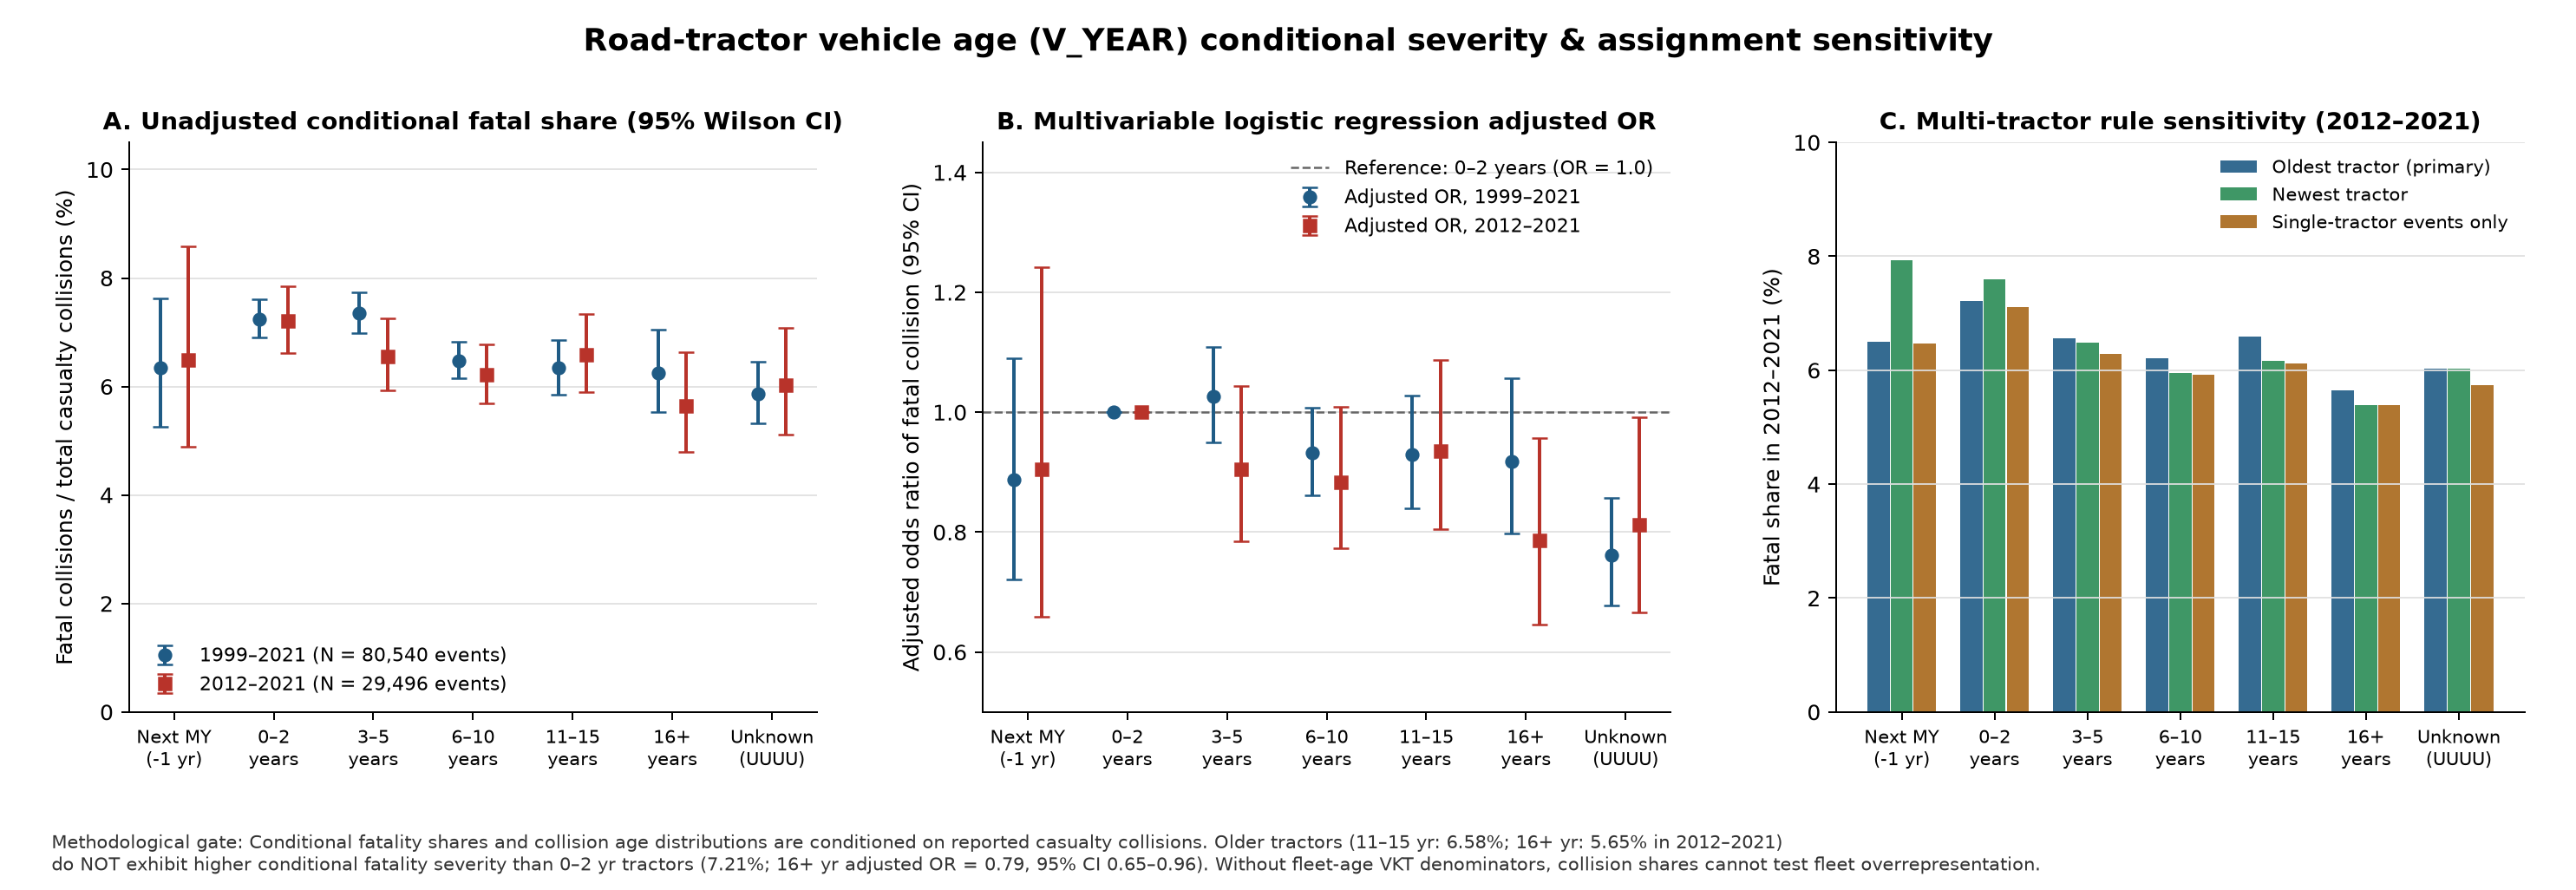

In [3]:
display(Image(filename=str(root / "reports/figures/vehicle_age_conditional_severity.png")))